# 07 — Model Evaluation

In this notebook, we perform in-depth evaluation on our selected models:
1. Classification report (Precision, Recall, F1-Score)
2. Confusion Matrix visualization
3. ROC (Receiver Operating Characteristic) curve and AUC analysis
4. Threshold sensitivity analysis for proactive HR retention

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
models_dir = '../models' if os.path.exists('../models') else 'models'

X_test = pd.read_csv(f'{data_dir}/X_test.csv')
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()

artifact = joblib.load(f'{models_dir}/attrition_model.pkl')
lr_model = artifact['lr_model']
rf_model = artifact['rf_model']

print("Loaded test data and model artifacts successfully.")

Loaded test data and model artifacts successfully.


## 1. Classification Reports

In [2]:
print("=== Logistic Regression Classification Report ===")
y_pred_lr = lr_model.predict(X_test)
print(classification_report(y_test, y_pred_lr, target_names=['Stay', 'Leave']))

print("\n=== Random Forest Classification Report ===")
y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=['Stay', 'Leave']))

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

        Stay       0.92      0.77      0.84       247
       Leave       0.36      0.66      0.46        47

    accuracy                           0.76       294
   macro avg       0.64      0.72      0.65       294
weighted avg       0.83      0.76      0.78       294


=== Random Forest Classification Report ===
              precision    recall  f1-score   support

        Stay       0.85      0.98      0.91       247
       Leave       0.44      0.09      0.14        47

    accuracy                           0.84       294
   macro avg       0.65      0.53      0.53       294
weighted avg       0.78      0.84      0.79       294



## 2. Confusion Matrix Visualizations

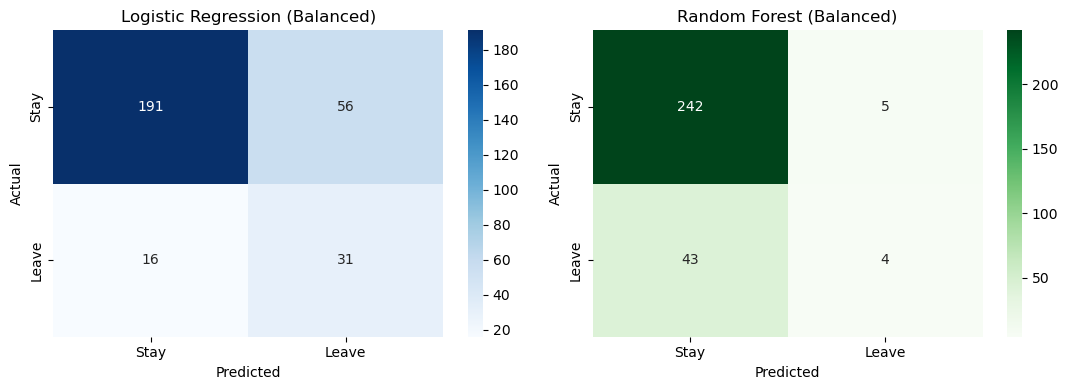

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Stay', 'Leave'], yticklabels=['Stay', 'Leave'])
axes[0].set_title('Logistic Regression (Balanced)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Stay', 'Leave'], yticklabels=['Stay', 'Leave'])
axes[1].set_title('Random Forest (Balanced)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 3. ROC Curves & AUC Comparison

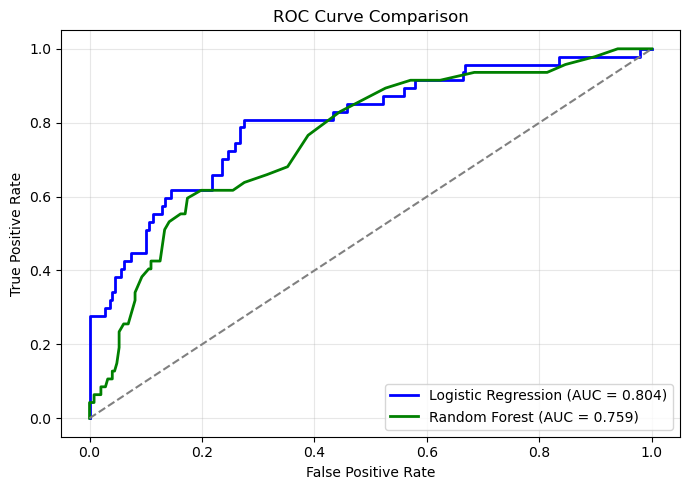

In [4]:
y_proba_lr = lr_model.predict_proba(X_test)[:, 1]
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

auc_lr = roc_auc_score(y_test, y_proba_lr)
auc_rf = roc_auc_score(y_test, y_proba_rf)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, color='blue', lw=2, label=f'Logistic Regression (AUC = {auc_lr:.3f})')
plt.plot(fpr_rf, tpr_rf, color='green', lw=2, label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Business Takeaway on Evaluation Metrics

In Employee Attrition:
- **False Negatives (Type II Error)**: Predicting an employee will stay when they actually leave is expensive (recruiting and replacement cost is 50-100% of annual salary).
- **False Positives (Type I Error)**: Predicting an employee might leave when they stay simply results in proactive engagement, check-ins, or recognition.
- Therefore, **Recall** and **ROC-AUC** are the primary decision metrics for HR interventions.